In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("nba_games_stats.csv")

print(df.head())

   Unnamed: 0 Team  Game      Date  Home Opponent WINorLOSS  TeamPoints  \
0           1  ATL     1  10/29/14  Away      TOR         L         102   
1           2  ATL     2   11/1/14  Home      IND         W         102   
2           3  ATL     3   11/5/14  Away      SAS         L          92   
3           4  ATL     4   11/7/14  Away      CHO         L         119   
4           5  ATL     5   11/8/14  Home      NYK         W         103   

   OpponentPoints  FieldGoals  ...  Opp.FreeThrows  Opp.FreeThrowsAttempted  \
0             109          40  ...              27                       33   
1              92          35  ...              18                       21   
2              94          38  ...              27                       38   
3             122          43  ...              20                       27   
4              96          33  ...               8                       11   

   Opp.FreeThrows.  Opp.OffRebounds  Opp.TotalRebounds  Opp.Assists  \
0  

In [4]:
print(df.shape)
print(df.columns)

(9840, 41)
Index(['Unnamed: 0', 'Team', 'Game', 'Date', 'Home', 'Opponent', 'WINorLOSS',
       'TeamPoints', 'OpponentPoints', 'FieldGoals', 'FieldGoalsAttempted',
       'FieldGoals.', 'X3PointShots', 'X3PointShotsAttempted', 'X3PointShots.',
       'FreeThrows', 'FreeThrowsAttempted', 'FreeThrows.', 'OffRebounds',
       'TotalRebounds', 'Assists', 'Steals', 'Blocks', 'Turnovers',
       'TotalFouls', 'Opp.FieldGoals', 'Opp.FieldGoalsAttempted',
       'Opp.FieldGoals.', 'Opp.3PointShots', 'Opp.3PointShotsAttempted',
       'Opp.3PointShots.', 'Opp.FreeThrows', 'Opp.FreeThrowsAttempted',
       'Opp.FreeThrows.', 'Opp.OffRebounds', 'Opp.TotalRebounds',
       'Opp.Assists', 'Opp.Steals', 'Opp.Blocks', 'Opp.Turnovers',
       'Opp.TotalFouls'],
      dtype='str')


In [5]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9840 entries, 0 to 9839
Data columns (total 41 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                9840 non-null   int64  
 1   Team                      9840 non-null   str    
 2   Game                      9840 non-null   int64  
 3   Date                      9840 non-null   str    
 4   Home                      9840 non-null   str    
 5   Opponent                  9840 non-null   str    
 6   WINorLOSS                 9840 non-null   str    
 7   TeamPoints                9840 non-null   int64  
 8   OpponentPoints            9840 non-null   int64  
 9   FieldGoals                9840 non-null   int64  
 10  FieldGoalsAttempted       9840 non-null   int64  
 11  FieldGoals.               9840 non-null   float64
 12  X3PointShots              9840 non-null   int64  
 13  X3PointShotsAttempted     9840 non-null   int64  
 14  X3PointShots.      

In [6]:
# Check missing values
print(df.isnull().sum())

Unnamed: 0                  0
Team                        0
Game                        0
Date                        0
Home                        0
Opponent                    0
WINorLOSS                   0
TeamPoints                  0
OpponentPoints              0
FieldGoals                  0
FieldGoalsAttempted         0
FieldGoals.                 0
X3PointShots                0
X3PointShotsAttempted       0
X3PointShots.               0
FreeThrows                  0
FreeThrowsAttempted         0
FreeThrows.                 0
OffRebounds                 0
TotalRebounds               0
Assists                     0
Steals                      0
Blocks                      0
Turnovers                   0
TotalFouls                  0
Opp.FieldGoals              0
Opp.FieldGoalsAttempted     0
Opp.FieldGoals.             0
Opp.3PointShots             0
Opp.3PointShotsAttempted    0
Opp.3PointShots.            0
Opp.FreeThrows              0
Opp.FreeThrowsAttempted     0
Opp.FreeTh

In [7]:
# Statistical summary
df.describe()

,Unnamed: 0,Game,TeamPoints,OpponentPoints,FieldGoals,FieldGoalsAttempted,FieldGoals.,X3PointShots,X3PointShotsAttempted,X3PointShots.,...,Opp.FreeThrows,Opp.FreeThrowsAttempted,Opp.FreeThrows.,Opp.OffRebounds,Opp.TotalRebounds,Opp.Assists,Opp.Steals,Opp.Blocks,Opp.Turnovers,Opp.TotalFouls
count,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,...,9840.00000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000
mean,11960.157012,41.500000,103.652337,103.652337,38.602439,84.902439,0.455689,9.126829,25.623679,0.354321,...,17.32063,22.749390,0.762395,10.287602,43.520630,22.546545,7.750508,4.827642,13.638618,20.058537
std,18654.867508,23.670804,12.188043,12.188043,5.029992,7.130043,0.054711,3.598084,7.102501,0.097782,...,6.00262,7.390451,0.104297,3.807120,6.410428,5.122989,2.958886,2.536845,3.869543,4.317611
min,1.000000,1.000000,64.000000,64.000000,19.000000,60.000000,0.271000,0.000000,4.000000,0.000000,...,1.00000,1.000000,0.143000,0.000000,20.000000,6.000000,0.000000,0.000000,2.000000,7.000000
25%,2537.750000,21.000000,95.000000,95.000000,35.000000,80.000000,0.418000,7.000000,21.000000,0.290000,...,13.00000,18.000000,0.696000,8.000000,39.000000,19.000000,6.000000,3.000000,11.000000,17.000000
50%,5141.500000,41.500000,103.000000,103.000000,38.000000,85.000000,0.455000,9.000000,25.000000,0.353000,...,17.00000,22.000000,0.769000,10.000000,43.000000,22.000000,8.000000,5.000000,13.000000,20.000000
75%,7715.250000,62.000000,112.000000,112.000000,42.000000,89.000000,0.494000,11.000000,30.000000,0.419000,...,21.00000,27.000000,0.833000,13.000000,48.000000,26.000000,10.000000,6.000000,16.000000,23.000000
max,82119.000000,82.000000,149.000000,149.000000,58.000000,129.000000,0.684000,25.000000,61.000000,0.750000,...,44.00000,64.000000,1.000000,38.000000,81.000000,47.000000,21.000000,18.000000,29.000000,42.000000


In [8]:
df = df.drop(columns=['Unnamed: 0'])

print("Updated dataset shape:", df.shape)

Updated dataset shape: (9840, 40)


In [10]:
print(df['Home'].value_counts())

Home
Away    4920
Home    4920
Name: count, dtype: int64


In [11]:
print(df['WINorLOSS'].value_counts())

WINorLOSS
L    4920
W    4920
Name: count, dtype: int64


In [12]:
# Convert categorical columns into numerical values

df['Home'] = df['Home'].map({'Home': 1, 'Away': 0})

df['WINorLOSS'] = df['WINorLOSS'].map({'W': 1, 'L': 0})

print(df[['Home', 'WINorLOSS']].head())

   Home  WINorLOSS
0     0          0
1     1          1
2     0          0
3     0          0
4     1          1


In [13]:
df = df.drop(columns=['Team', 'Game', 'Date', 'Opponent'])

print(df.head())

   Home  WINorLOSS  TeamPoints  OpponentPoints  FieldGoals  \
0     0          0         102             109          40   
1     1          1         102              92          35   
2     0          0          92              94          38   
3     0          0         119             122          43   
4     1          1         103              96          33   

   FieldGoalsAttempted  FieldGoals.  X3PointShots  X3PointShotsAttempted  \
0                   80        0.500            13                     22   
1                   69        0.507             7                     20   
2                   92        0.413             8                     25   
3                   93        0.462            13                     33   
4                   81        0.407             9                     22   

   X3PointShots.  ...  Opp.FreeThrows  Opp.FreeThrowsAttempted  \
0          0.591  ...              27                       33   
1          0.350  ...              18 

In [14]:
X = df.drop(columns=['WINorLOSS'])
y = df['WINorLOSS']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (9840, 35)
Output shape: (9840,)


In [15]:
print("Missing values:")
print(X.isnull().sum().sum())

Missing values:
0


In [16]:
# Separate independent and dependent variables

X = df.drop(columns=['Home'])
y = df['Home']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (9840, 35)
Output shape: (9840,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=1
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6592, 35)
Testing data: (3248, 35)


In [18]:
from sklearn.linear_model import LogisticRegression

logmodel = LogisticRegression(max_iter=1000)

logmodel.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


C:\Users\mrity\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [21]:
logmodel = LogisticRegression(max_iter=5000)

logmodel.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [22]:
predictions = logmodel.predict(X_test_scaled)

print("Predictions:")
print(predictions[:20])

Predictions:
[1 0 0 0 0 1 1 1 1 0 1 1 0 0 0 1 0 0 1 0]


In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 60.06773399014779 %


In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 941  721]
 [ 576 1010]]


In [25]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, predictions))

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.57      0.59      1662
           1       0.58      0.64      0.61      1586

    accuracy                           0.60      3248
   macro avg       0.60      0.60      0.60      3248
weighted avg       0.60      0.60      0.60      3248



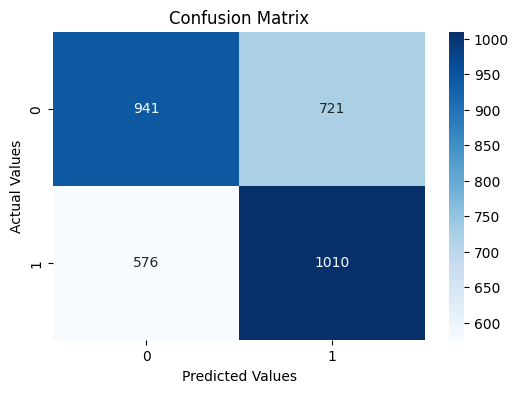

In [26]:
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Confusion Matrix')

plt.show()

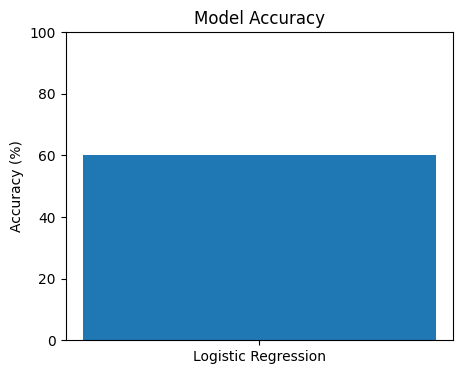

In [27]:
plt.figure(figsize=(5, 4))

plt.bar(['Logistic Regression'], [accuracy * 100])

plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy')

plt.ylim(0, 100)
plt.show()

### Conclusion

In this assignment, Logistic Regression was implemented using Python and the NBA game statistics dataset to predict whether a game was played at home or away.

The dataset was preprocessed, features were selected, and the data was divided into training and testing sets. StandardScaler was used for feature scaling before training the model.

The model achieved an accuracy of approximately 60.07% on the test dataset. Its performance was evaluated using a confusion matrix and classification report.

The results demonstrate that Logistic Regression can classify home and away games using game statistics, although there is scope for improving its prediction accuracy.
